In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

df = pd.read_csv(PROC / "wfp_food_prices_phl.csv", parse_dates=["date"])
df["ym"] = df["date"].dt.to_period("M")
print(df.shape)

(210339, 17)


In [2]:
cov = (df.groupby("ym")
         .agg(rows=("price", "size"),
              markets=("market_id", "nunique"),
              commodities=("commodity_id", "nunique")))

full_calendar = pd.period_range(df["ym"].min(), df["ym"].max(), freq="M")
missing = full_calendar.difference(cov.index)

print("Months in full calendar:", len(full_calendar))
print("Months with data       :", len(cov))
print("Missing months         :", [str(m) for m in missing])

# Reindex so missing months show as zero rows (needed for plotting and later resampling)
cov = cov.reindex(full_calendar, fill_value=0)
cov.index.name = "ym"
cov.to_csv(TAB / "02_monthly_coverage.csv")

print("\nThin months (< 100 rows):")
print(cov[cov["rows"] < 100])

Months in full calendar: 126
Months with data       : 124
Missing months         : ['2020-03', '2020-04']

Thin months (< 100 rows):
         rows  markets  commodities
ym                                 
2019-06    20       16            2
2019-07    34        6            7
2019-08    28        6            5
2019-09    33        6            7
2019-10    34        6            7
2019-11    28        5            7
2019-12    21        5            6
2020-01    34        6            7
2020-02    23        5            6
2020-03     0        0            0
2020-04     0        0            0


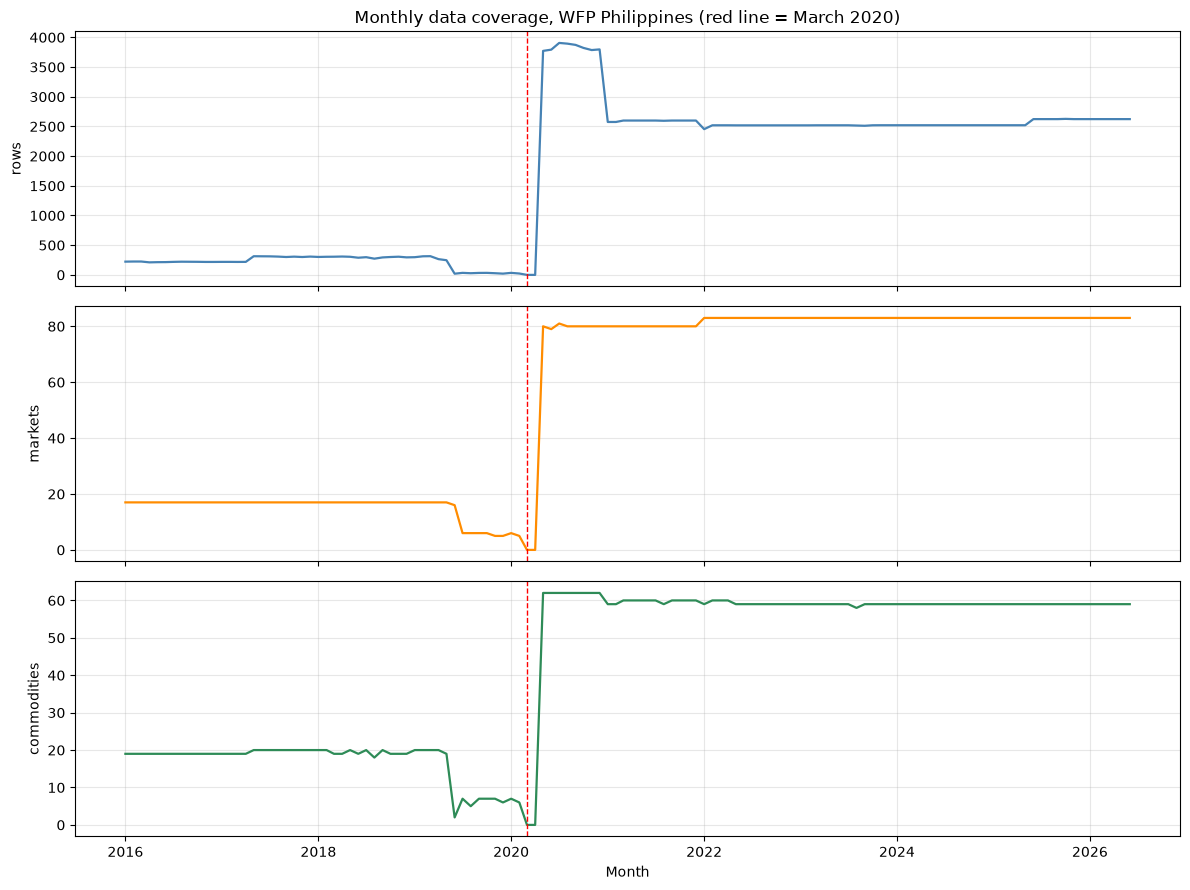

In [3]:
x = cov.index.to_timestamp()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, col, color in zip(axes, ["rows", "markets", "commodities"],
                          ["steelblue", "darkorange", "seagreen"]):
    ax.plot(x, cov[col], color=color, lw=1.6)
    ax.set_ylabel(col)
    ax.axvline(pd.Timestamp("2020-03-01"), color="red", ls="--", lw=1)
    ax.grid(alpha=0.3)

axes[0].set_title("Monthly data coverage, WFP Philippines (red line = March 2020)")
axes[-1].set_xlabel("Month")
plt.tight_layout()
plt.savefig(FIG / "02_monthly_coverage.png", dpi=150)
plt.show()

In [4]:
print(cov.loc["2019-04":"2020-06"])

         rows  markets  commodities
ym                                 
2019-04   265       17           20
2019-05   247       17           19
2019-06    20       16            2
2019-07    34        6            7
2019-08    28        6            5
2019-09    33        6            7
2019-10    34        6            7
2019-11    28        5            7
2019-12    21        5            6
2020-01    34        6            7
2020-02    23        5            6
2020-03     0        0            0
2020-04     0        0            0
2020-05  3772       80           62
2020-06  3793       79           62


In [5]:
# ---- Research design parameters: change here only ----
COVID_START = pd.Timestamp("2020-03-01")   # Luzon community quarantine began mid-March 2020
COVID_END   = pd.Timestamp("2023-05-31")   # WHO ended the global health emergency on 5 May 2023
# -------------------------------------------------------

def tag_period(d):
    if d < COVID_START:
        return "Pre-COVID"
    elif d <= COVID_END:
        return "During-COVID"
    return "Post-COVID"

df["period"] = df["date"].map(tag_period)
df["period"] = pd.Categorical(df["period"],
                              ["Pre-COVID", "During-COVID", "Post-COVID"], ordered=True)

period_summary = (df.groupby("period", observed=True)
                    .agg(rows=("price", "size"),
                         months=("ym", "nunique"),
                         markets=("market_id", "nunique"),
                         commodities=("commodity_id", "nunique"),
                         start=("date", "min"),
                         end=("date", "max")))
display(period_summary)
period_summary.to_csv(TAB / "02_period_summary.csv")

,rows,months,markets,commodities,start,end
period,,,,,,
Pre-COVID,11246,50,17,20,2016-01-15,2020-02-15
During-COVID,104527,37,83,62,2020-05-15,2023-05-15
Post-COVID,94566,37,83,59,2023-06-15,2026-06-15


In [6]:
df.to_csv(PROC / "wfp_prices_tagged.csv", index=False)
print("Saved:", PROC / "wfp_prices_tagged.csv")

Saved: ..\data\processed\wfp_prices_tagged.csv
